# Week 3: Learning the model (JAX)

The NumPy notebook runs one learner at a time. This one does three things that
need many runs at once.

1. **Check the derivations.** `jax.grad` differentiates the log joint with respect
   to all four parameters, the truncation normaliser included, and the results are
   compared with the formulas of Lessons 2 and 3.
2. **A thousand learners.** One run of a learning rule is one path through one
   sequence of sounds. A thousand independent sequences, run side by side, show
   where the point rule settles on average and how widely single runs scatter.
3. **The drift, swept.** Lesson 4 found where the point rule's drift, its expected
   update, vanishes by quadrature. Here it is estimated by settling a hundred
   thousand trials at once for each value on a grid, for both the point rule and
   the posterior-averaged rule.

The random numbers here come from JAX's own generator, not the one the widgets use,
so individual runs differ from those on the course pages; averages agree within
their sampling error.

### AI use

This course notebook was developed with substantial assistance from Claude
(Anthropic) and revised with Codex (OpenAI), under Jonathan Shock's direction.
AI contributed to explanations and code. See [AI use and attribution](https://shocklab.github.io/Active-Inference-course/ai-use.html)
for the review process and its limits.

In [1]:
import time
import jax
import jax.numpy as jnp
from jax import grad, jit, vmap
from jax.scipy.special import ndtr
import numpy as np
import matplotlib.pyplot as plt

jax.config.update('jax_enable_x64', True)
print(jax.__version__, jax.devices())

0.6.2 [CpuDevice(id=0)]


## 1. Does the derivation hold up?

`ell` below is the log joint with every constant kept, written as a function of the
four parameters. `ndtr` is the standard normal distribution function, so
`ndtr(dp / sqrt(vp))` is the truncation normaliser. JAX differentiates it; the
hand-derived formulas are written out separately.

In [2]:
U, D_PRIOR, VAR_PRIOR, THETA, VAR_OBS = 0.5, 2.0, 1.0, 1.0, 0.1


def ell(params, d, u=U):
    dp, vp, th, vu = params
    return (-(d - dp) ** 2 / (2 * vp) - 0.5 * jnp.log(2 * jnp.pi * vp)
            - jnp.log(ndtr(dp / jnp.sqrt(vp)))
            - (u - th / d ** 2) ** 2 / (2 * vu) - 0.5 * jnp.log(2 * jnp.pi * vu))


def by_hand(params, d, u=U):
    dp, vp, th, vu = params
    ep = (dp - d) / vp
    eu = (u - th / d ** 2) / vu
    lam = jnp.exp(-dp ** 2 / (2 * vp)) / jnp.sqrt(2 * jnp.pi * vp) / ndtr(dp / jnp.sqrt(vp))
    return jnp.array([-ep - lam,
                      0.5 * (ep ** 2 - 1 / vp) + dp * lam / (2 * vp),
                      eu / d ** 2,
                      0.5 * (eu ** 2 - 1 / vu)])


auto = jit(vmap(grad(ell), in_axes=(0, None)))
hand = jit(vmap(by_hand, in_axes=(0, None)))

key = jax.random.PRNGKey(0)
k1, k2, k3, k4 = jax.random.split(key, 4)
n = 10000
P = jnp.stack([jax.random.uniform(k1, (n,), minval=0.5, maxval=4.0),
               jax.random.uniform(k2, (n,), minval=0.2, maxval=3.0),
               jax.random.uniform(k3, (n,), minval=0.3, maxval=3.0),
               jax.random.uniform(k4, (n,), minval=0.02, maxval=1.0)], axis=1)
for d in (0.8, 1.55, 3.0):
    gap = jnp.abs(auto(P, d) - hand(P, d)).max(axis=0)
    print(f'd = {d}: largest disagreement for (dp, vp, theta, vu) over {n} parameter sets:', np.asarray(gap))

d = 0.8: largest disagreement for (dp, vp, theta, vu) over 10000 parameter sets: [1.77635684e-15 2.84217094e-14 5.68434189e-14 3.63797881e-12]
d = 1.55: largest disagreement for (dp, vp, theta, vu) over 10000 parameter sets: [1.77635684e-15 1.42108547e-14 1.77635684e-15 1.13686838e-13]
d = 3.0: largest disagreement for (dp, vp, theta, vu) over 10000 parameter sets: [1.77635684e-15 1.42108547e-14 4.44089210e-16 5.68434189e-14]


## 2. The inner loop, vectorised

The same capped ascent as the NumPy notebook and the widgets. A batch runs until
every trial's last step is below `TOL`, or `KMAX` steps have run, and `settle`
returns the number of trials still moving at the end so that every later section can
check it.

In [3]:
ETA, KMAX, TOL = 0.05, 2000, 1e-12


def settle(u, dp, vp, th, vu):
    """Returns the settled states and the number of trials whose last step was
    still above TOL when the loop stopped."""
    def step(d):
        gp = -2.0 * th / d ** 3
        g = (dp - d) / vp + (u - th / d ** 2) / vu * gp
        cap = 1.0 / (1.0 / vp + gp ** 2 / vu)
        return jnp.maximum(jnp.minimum(ETA, cap) * g, -0.5 * d)

    def cond(state):
        k, d, s = state
        return (k < KMAX) & (jnp.max(jnp.abs(s)) >= TOL)

    def body(state):
        k, d, _ = state
        s = step(d)
        return k + 1, d + s, s

    d0 = jnp.full_like(u, dp)
    _, d, s = jax.lax.while_loop(cond, body, (0, d0, jnp.full_like(u, 1.0)))
    return d, jnp.sum(jnp.abs(s) >= TOL)


def world(key, n, loc, var, th, vu):
    # draw from the truncated prior by inverting its distribution function
    k1, k2 = jax.random.split(key)
    lo = ndtr(-loc / jnp.sqrt(var))
    p = lo + (1 - lo) * jax.random.uniform(k1, (n,), minval=1e-12, maxval=1 - 1e-12)
    d = loc + jnp.sqrt(var) * jax.scipy.special.ndtri(p)
    d = jnp.maximum(d, 1e-6)
    return d, th / d ** 2 + jnp.sqrt(vu) * jax.random.normal(k2, (n,))


d_true, u = world(jax.random.PRNGKey(1), 5, D_PRIOR, VAR_PRIOR, THETA, VAR_OBS)
d1, still = settle(u, D_PRIOR, VAR_PRIOR, THETA, VAR_OBS)
gp = -2.0 * THETA / d1 ** 3
print('gradient left at the settled states:', np.asarray((D_PRIOR - d1) / VAR_PRIOR + (u - THETA / d1 ** 2) / VAR_OBS * gp))
print('trials still moving:', int(still))
print('settled at Week 2\'s sound:', float(settle(jnp.array([0.5]), D_PRIOR, VAR_PRIOR, THETA, VAR_OBS)[0][0]))

gradient left at the settled states: [-6.63899491e-12  1.82214244e-11  1.11022302e-16 -4.88498131e-15
  1.65778502e-11]
trials still moving: 0
settled at Week 2's sound: 1.5500361404030556


## 3. A thousand learners

Each learner hears its own sequence of 2000 sounds from a world equal to Week 2's
model and learns the sensory variance by the point rule, starting at the truth. As in
the NumPy notebook, a trial whose inference did not settle changes nothing.
`lax.scan` runs the trials in order for one learner and `vmap` runs a thousand
learners side by side.

1000 learners x 2000 trials in 1.4 s; trials that did not settle: 0
mean over learners of each run's second-half average: 0.02757
spread (standard deviation) across learners:            0.00266
the truth:                                              0.1


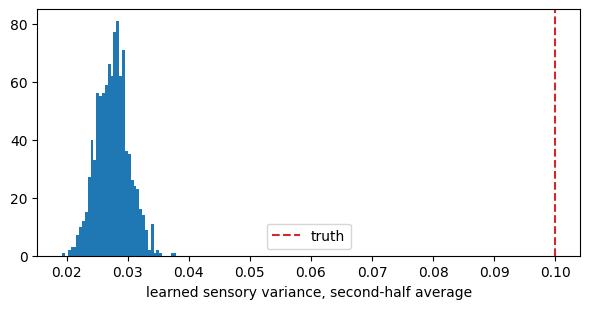

In [4]:
BETA, NT, NL = 0.01, 2000, 1000


def learner(key, vu_world=VAR_OBS):
    _, us = world(key, NT, D_PRIOR, VAR_PRIOR, THETA, vu_world)

    def step(vu, u):
        d, still = settle(u[None], D_PRIOR, VAR_PRIOR, THETA, vu)
        r2 = (u - THETA / d[0] ** 2) ** 2
        # a trial that did not settle leaves the variance as it was
        vu = jnp.where(still == 0, vu * jnp.exp(BETA * 0.5 * (r2 / vu - 1.0)), vu)
        return vu, (vu, still)
    _, (hist, still) = jax.lax.scan(step, VAR_OBS, us)
    return hist, still.sum()


many = jit(vmap(learner))
keys = jax.random.split(jax.random.PRNGKey(2), NL)
t0 = time.time()
H, STILL = many(keys)
H = H.block_until_ready()
print(f'{NL} learners x {NT} trials in {time.time() - t0:.1f} s; trials that did not settle: {int(STILL.sum())}')

late = H[:, NT // 2:].mean(axis=1)
print(f'mean over learners of each run\'s second-half average: {late.mean():.5f}')
print(f'spread (standard deviation) across learners:            {late.std():.5f}')
print(f'the truth:                                              {VAR_OBS}')

plt.figure(figsize=(6, 3.2))
plt.hist(np.asarray(late), bins=40)
plt.axvline(VAR_OBS, ls='--', c='C3', label='truth')
plt.xlabel('learned sensory variance, second-half average'); plt.legend()
plt.tight_layout(); plt.show()

Every learner starts at the truth and moves away from it. The thousand runs cluster
far below the truth, which is the bias, and their spread about their own centre is
the noise of a single run; the two are of very different sizes.

## 4. The drift, swept

For each value of the learned sensory variance on a grid, settle a large batch of
trials drawn from the world and average the point rule's update. Then do the same
with the squared residual replaced by its posterior average, computed by the same two
routes as `post_r2` in the NumPy notebook and the widget: over the likelihood's window
in residual coordinates when the prior can reach it, and over log distance for a
quiet or negative observation. A sweep down to small variances meets many negative
observations, so the second route matters here.

negative observations, model variance 0.005: [1.07842137 4.11541549]  independent: 1.07842137 4.11541549


swept 25 values x 100000 trials, both rules, in 3.4 s
trials that did not settle, over the whole sweep: 0
point rule: drift vanishes near 0.0266
posterior-averaged rule: near 0.0997   (truth 0.1)


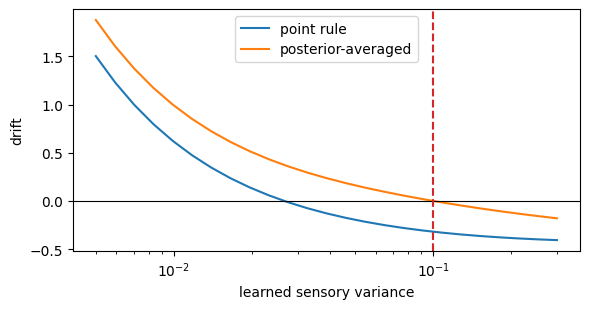

In [5]:
NB, NY = 100000, 801
_, U_BATCH = world(jax.random.PRNGKey(3), NB, D_PRIOR, VAR_PRIOR, THETA, VAR_OBS)


@jit
def point_update(vu):
    d, still = settle(U_BATCH, D_PRIOR, VAR_PRIOR, THETA, vu)
    return jnp.mean(0.5 * ((U_BATCH - THETA / d ** 2) ** 2 / vu - 1.0)), still


def post_r2(u, vu, dp=D_PRIOR, vp=VAR_PRIOR, th=THETA):
    """Posterior average of the squared residual for a batch of observations."""
    sd = jnp.sqrt(vu)
    t = jnp.linspace(0.0, 1.0, NY)
    tw = jnp.ones(NY).at[0].set(0.5).at[-1].set(0.5)
    near = u - 10 * sd > th / (dp + 12 * jnp.sqrt(vp)) ** 2
    # route 1: residual coordinates rho = u - y over +-10 sd, Jacobian y^(-3/2)
    rho = -10 * sd + 20 * sd * t
    y = jnp.where(near[:, None], u[:, None] - rho[None, :], 1.0)
    d = jnp.sqrt(th / y)
    lw1 = -rho[None, :] ** 2 / (2 * vu) - (d - dp) ** 2 / (2 * vp) - 1.5 * jnp.log(y)
    r1 = jnp.broadcast_to(rho[None, :] ** 2, y.shape)
    # route 2: log distance, from where the likelihood is negligible to past the mode
    up = jnp.maximum(u, 0.0)
    c = 2 * th * vp * (th / dp ** 2 + jnp.abs(u)) / vu
    db = dp + 12 * jnp.sqrt(vp) + c ** 0.25
    da = jnp.minimum(jnp.sqrt(th / (up + 12 * sd)), 0.5 * db)
    q = jnp.log(da)[:, None] + (jnp.log(db) - jnp.log(da))[:, None] * t[None, :]
    dq = jnp.exp(q)
    res = u[:, None] - th / dq ** 2
    lw2 = -res ** 2 / (2 * vu) - (dq - dp) ** 2 / (2 * vp) + q
    lw = jnp.where(near[:, None], lw1, lw2)
    r2 = jnp.where(near[:, None], r1, res ** 2)
    w = jnp.exp(lw - lw.max(axis=1, keepdims=True)) * tw[None, :]
    return (w * r2).sum(axis=1) / w.sum(axis=1)


print('negative observations, model variance 0.005:',
      np.asarray(post_r2(jnp.array([-1.0, -2.0]), 0.005)), ' independent: 1.07842137 4.11541549')


@jit
def post_update(vu):
    r2 = jax.lax.map(lambda ub: post_r2(ub, vu), U_BATCH.reshape(20, -1)).ravel()
    return jnp.mean(0.5 * (r2 / vu - 1.0))


grid = np.geomspace(0.005, 0.3, 25)
t0 = time.time()
pts = [point_update(v) for v in grid]
pu = np.array([float(a) for a, _ in pts])
qu = np.array([float(post_update(v)) for v in grid])
print(f'swept {len(grid)} values x {NB} trials, both rules, in {time.time() - t0:.1f} s')
print('trials that did not settle, over the whole sweep:', sum(int(b) for _, b in pts))


def crossing(xs, ys):
    i = np.where(np.sign(ys[:-1]) != np.sign(ys[1:]))[0][0]
    return np.exp(np.interp(0, [ys[i + 1], ys[i]], [np.log(xs[i + 1]), np.log(xs[i])]))


print(f'point rule: drift vanishes near {crossing(grid, pu):.4f}')
print(f'posterior-averaged rule: near {crossing(grid, qu):.4f}   (truth {VAR_OBS})')

plt.figure(figsize=(6, 3.2))
plt.semilogx(grid, pu, label='point rule'); plt.semilogx(grid, qu, label='posterior-averaged')
plt.axhline(0, c='k', lw=0.8); plt.axvline(VAR_OBS, ls='--', c='C3')
plt.xlabel('learned sensory variance'); plt.ylabel('drift'); plt.legend()
plt.tight_layout(); plt.show()

The point rule's crossing is Lesson 4's stationary point, estimated here by sampling
rather than by quadrature over the world, and it is where the thousand learners of
section 3 cluster. The posterior-averaged rule crosses at the truth, as the score
argument of Lesson 4 requires.